In [1]:
# Step 1: Load the Taxis Dataset
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Display the first five rows
print(df.head())

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   
2 2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5  2.36   
3 2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0  6.15   
4 2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0  1.10   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   
2    0.0  14.16  yellow  credit card          Alphabet City   
3    0.0  36.95  yellow  credit card              Hudson Sq   
4    0.0  13.40  yellow  credit card           Midtown East   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      



*   pandas is used for data handling
*   numpy is used for numerical operations
*   seaborn provides the taxis dataset and statistical visualizations
*   matplotlib is used to create charts
*   df.head() displays the first five rows






In [2]:
# Step 2: Check and Handle Missing Values
# Check missing values in each column
print(df.isnull().sum())

# Display columns that contain missing values
print(df.isnull().sum()[df.isnull().sum() > 0])

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


isnull().sum() counts missing values in each column.

In [3]:
# 2.2 Handle missing values
# Separate numerical and categorical columns
numerical_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include=["object", "category"]).columns

# Fill numerical missing values with the median
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values with the mode
for col in categorical_cols:
    if df[col].isnull().any() and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])

# Remove rows with missing critical values
df = df.dropna(subset=["pickup", "fare", "pickup_borough",
                       "payment", "distance", "tip"])

# Check missing values again
print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64




*   Numerical columns are filled using their median
*   Categorical columns are filled using their most frequent value (mode)
*   Rows missing critical visualization values are removed
*   The final statement checks whether any missing values remain







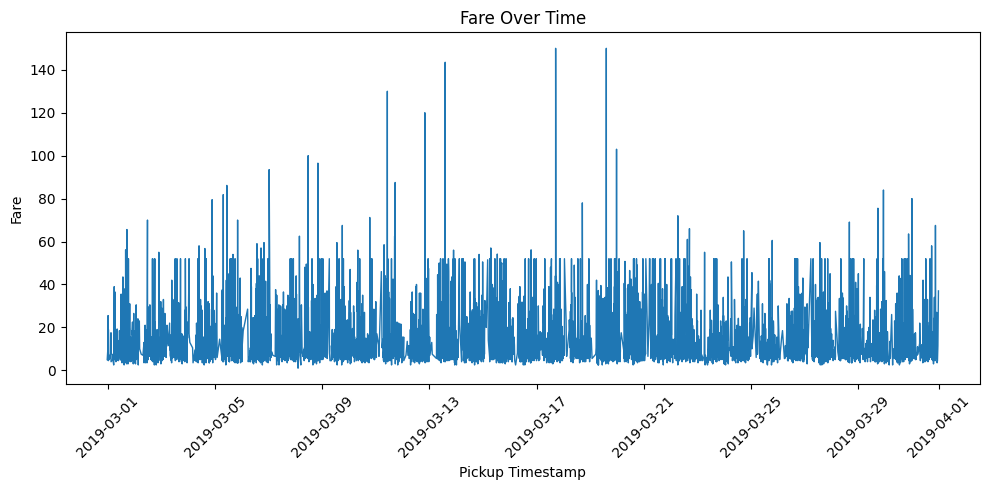

In [4]:
# Step 3: Visualizations Using Matplotlib and Pandas

# 3.1 Line Chart – Fare Over Time
# Convert pickup column to datetime
df["pickup"] = pd.to_datetime(df["pickup"])

# Sort data by pickup time
df = df.sort_values("pickup")

# Create line chart
plt.figure(figsize=(10, 5))
plt.plot(df["pickup"], df["fare"], linewidth=1)

plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The line chart shows how taxi fares vary over pickup time. Sorting the timestamps ensures that the line follows the correct time order.

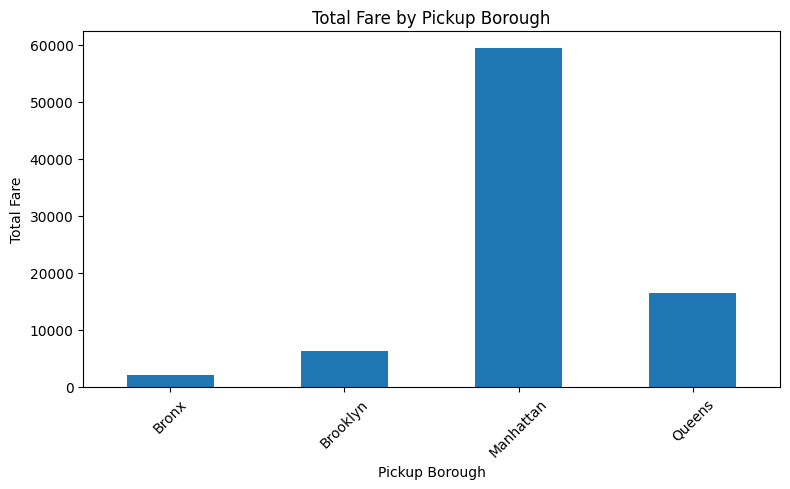

In [5]:
# 3.2 Bar Chart – Total Fare by Pickup Borough
# Calculate total fare for each borough
borough_fare = df.groupby("pickup_borough")["fare"].sum()

# Create bar chart
borough_fare.plot(kind="bar", figsize=(8, 5))

plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The bar chart compares the total fare collected from each pickup borough.

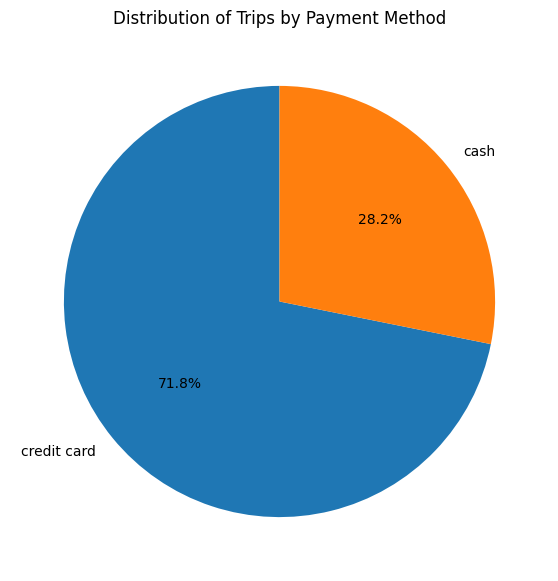

In [6]:
# 3.3 Pie Chart – Trips by Payment Method
# Count trips by payment method
payment_counts = df["payment"].value_counts()

# Create pie chart
plt.figure(figsize=(7, 7))
plt.pie(payment_counts, labels=payment_counts.index,
        autopct="%1.1f%%", startangle=90)

plt.title("Distribution of Trips by Payment Method")
plt.show()

The pie chart shows the percentage of trips paid for using each payment method.

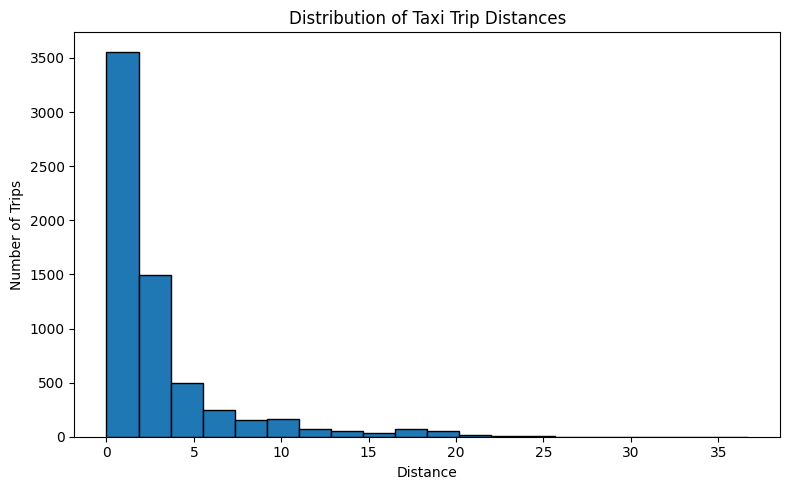

In [7]:
# 3.4 Histogram – Distribution of Distance
plt.figure(figsize=(8, 5))

plt.hist(df["distance"], bins=20, edgecolor="black")

plt.title("Distribution of Taxi Trip Distances")
plt.xlabel("Distance")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

The histogram shows how frequently different trip distances occur. The bins=20 setting divides the distances into 20 intervals.

<Figure size 900x500 with 0 Axes>

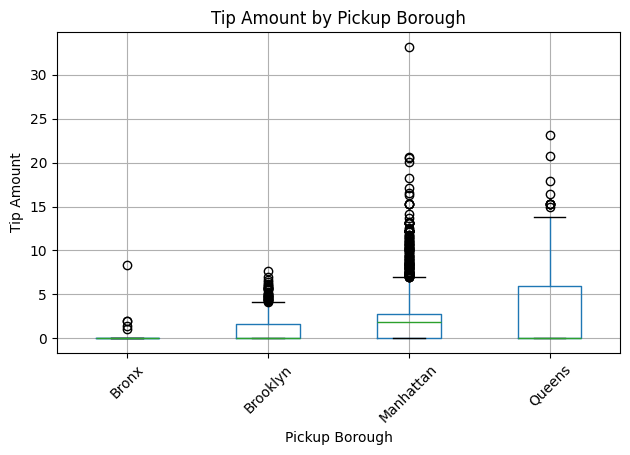

In [8]:
# 3.5 Box Plot – Tip Amount by Pickup Borough
plt.figure(figsize=(9, 5))

df.boxplot(column="tip", by="pickup_borough")

plt.title("Tip Amount by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The box plot compares tip distributions across boroughs and helps identify the median, spread, and possible outliers.

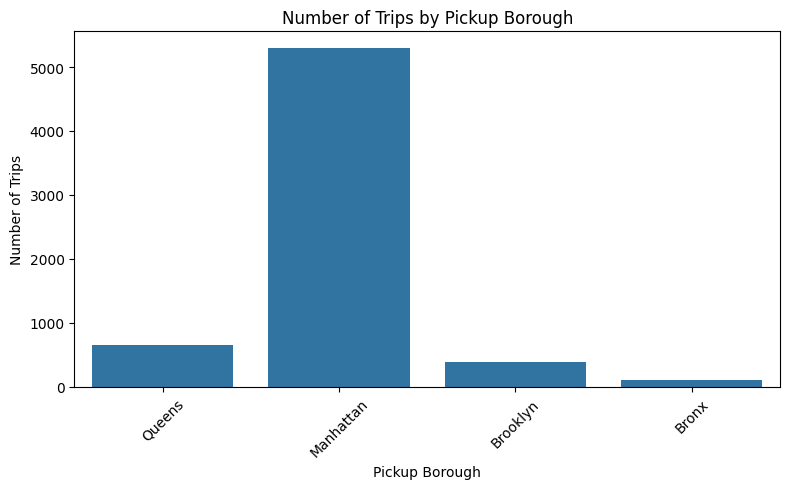

In [9]:
# Step 4: Visualizations Using Seaborn

# 4.1 Count Plot – Number of Trips by Pickup Borough
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="pickup_borough")

plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The count plot displays the number of taxi trips originating from each borough.

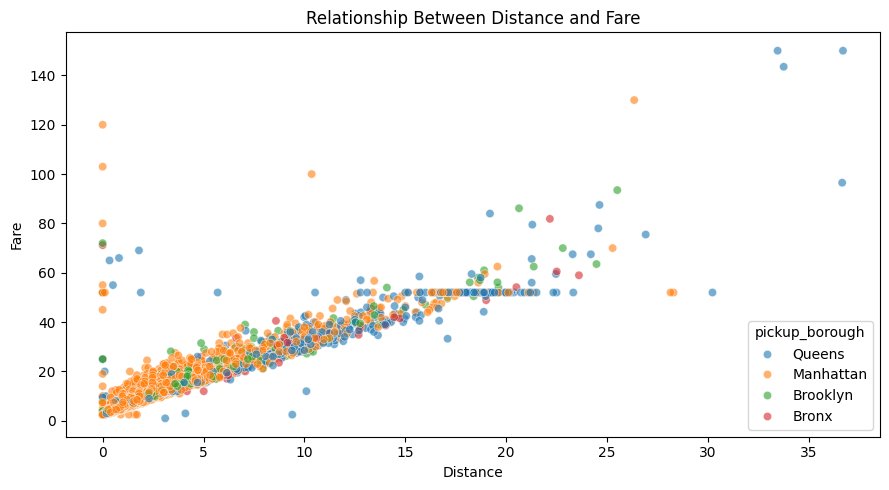

In [10]:
# 4.2 Scatter Plot – Distance vs Fare
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough",
    alpha=0.6
)

plt.title("Relationship Between Distance and Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

The scatter plot helps identify the relationship between trip distance and fare. Different colors represent different pickup boroughs.

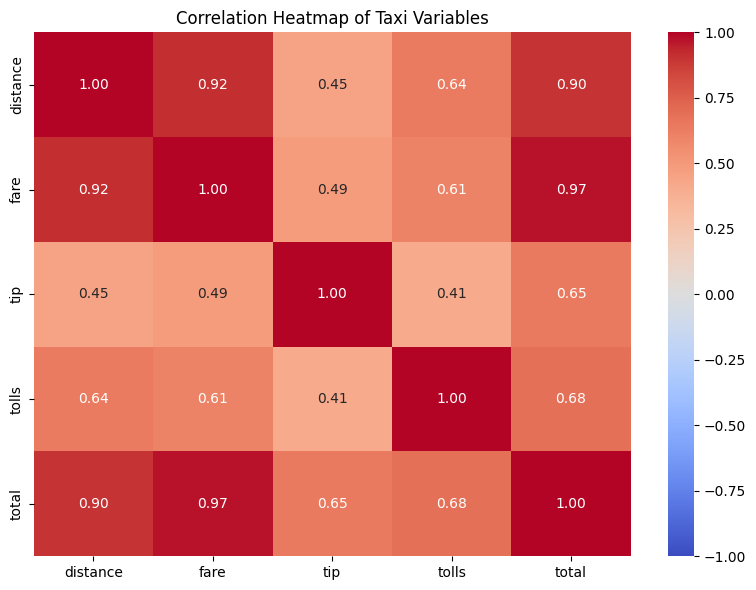

In [11]:
# 4.3 Heatmap – Correlation Between Numerical Variables
# Select numerical variables
numeric_data = df[["distance", "fare", "tip", "tolls", "total"]]

# Calculate correlation matrix
correlation = numeric_data.corr()

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(correlation, annot=True, cmap="coolwarm",
            fmt=".2f", vmin=-1, vmax=1)

plt.title("Correlation Heatmap of Taxi Variables")
plt.tight_layout()
plt.show()



*   Values near +1 indicate a strong positive relationship
*   Values near -1 indicate a strong negative relationship
*   Values near 0 indicate a weak linear relationship






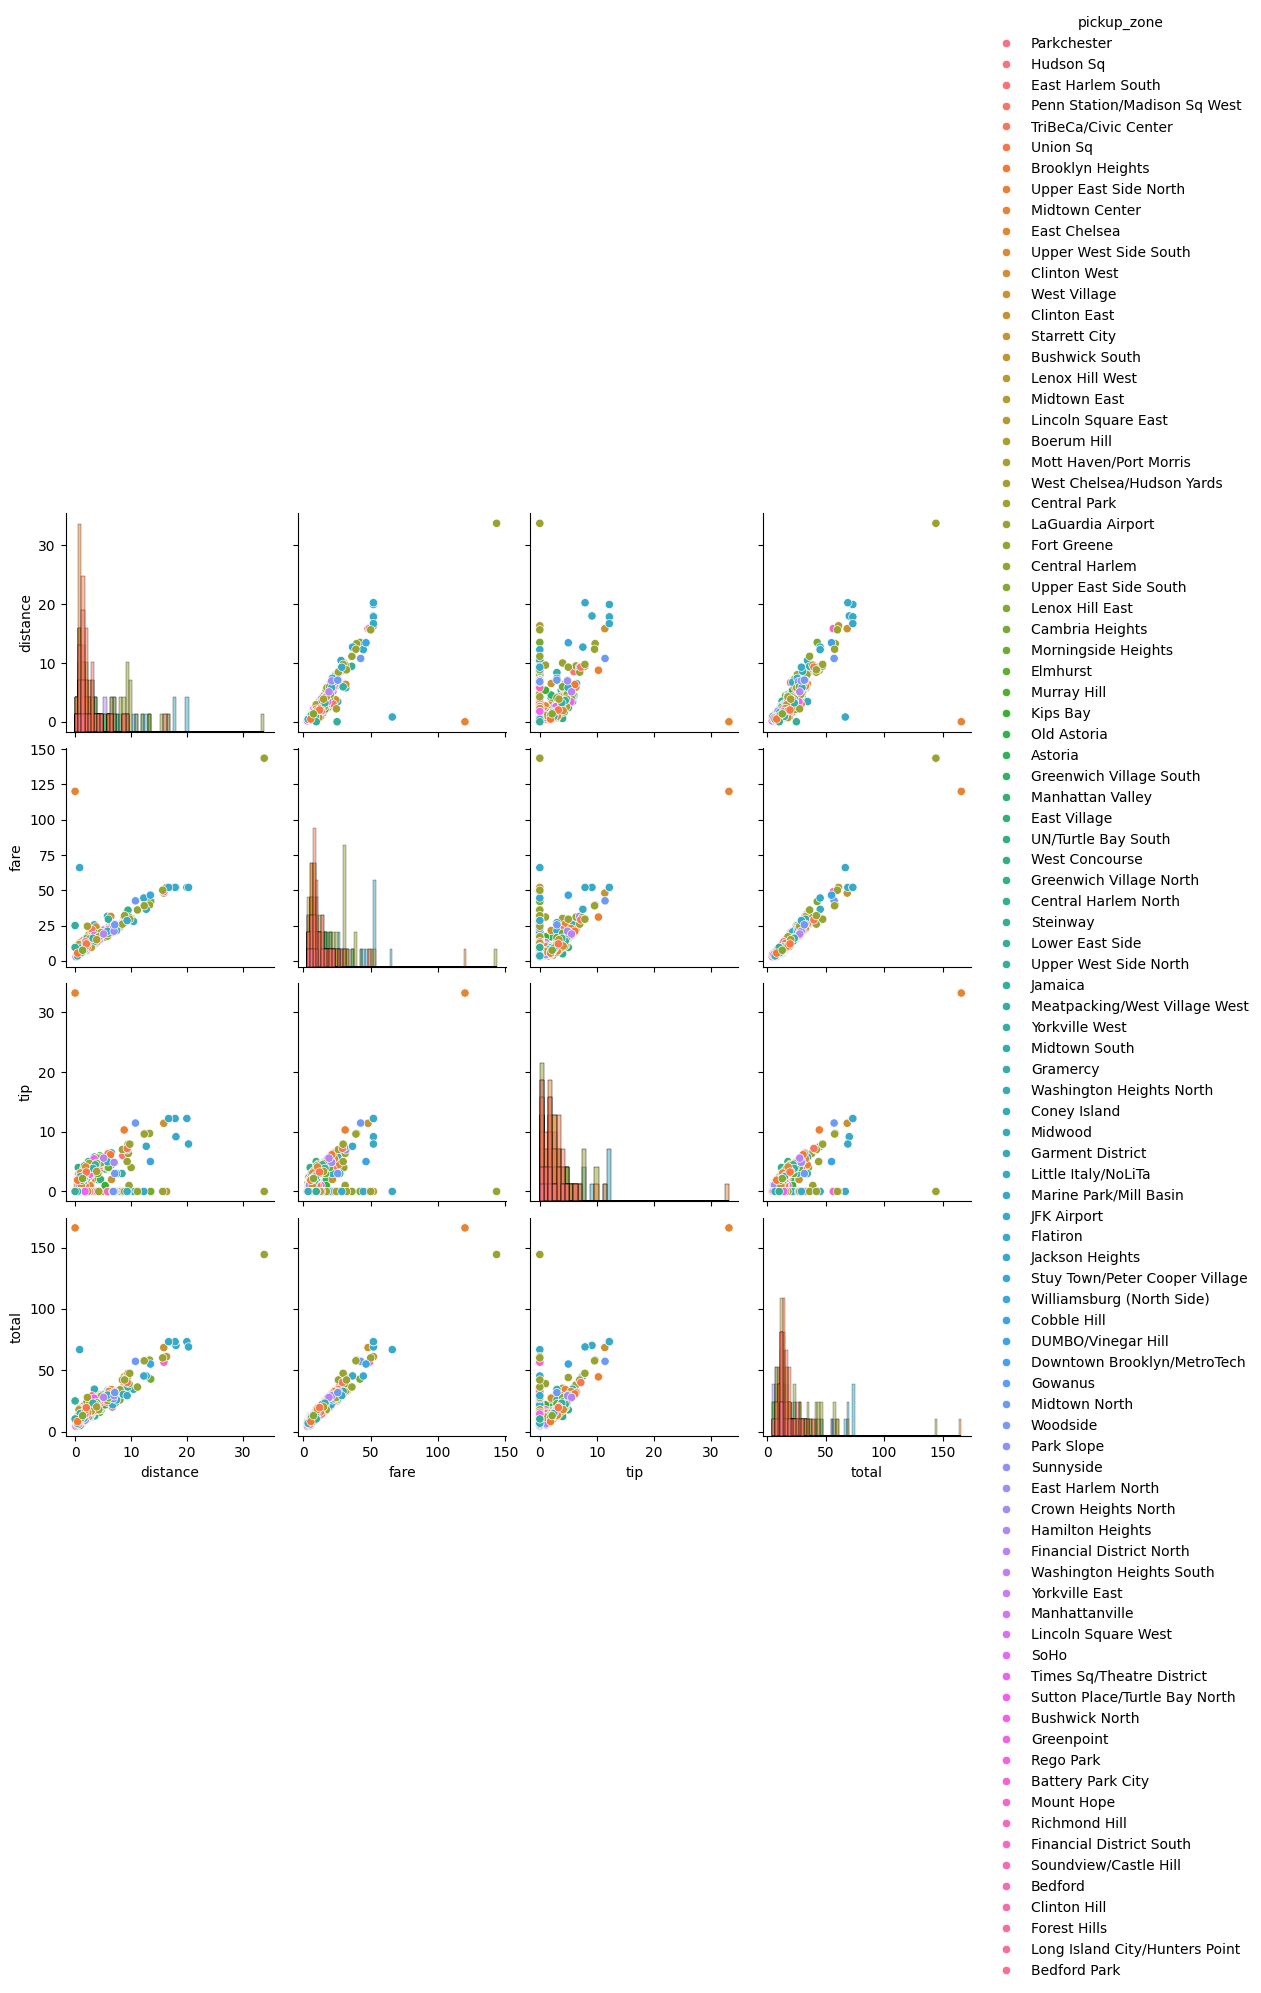

In [13]:
# 4.4 Pair Plot – Relationships Between Numerical Variables
# Select required columns and remove missing values
pair_data = df[["distance", "fare", "tip", "total",
                "pickup_zone"]].dropna()

# Use a sample to keep the plot readable
pair_data = pair_data.sample(
    n=min(500, len(pair_data)),
    random_state=42
)

# Create pair plot
sns.pairplot(
    pair_data,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    diag_kind="hist"
)

plt.show()

The pair plot displays pairwise relationships among distance, fare, tip, and total. The colors distinguish pickup zones.

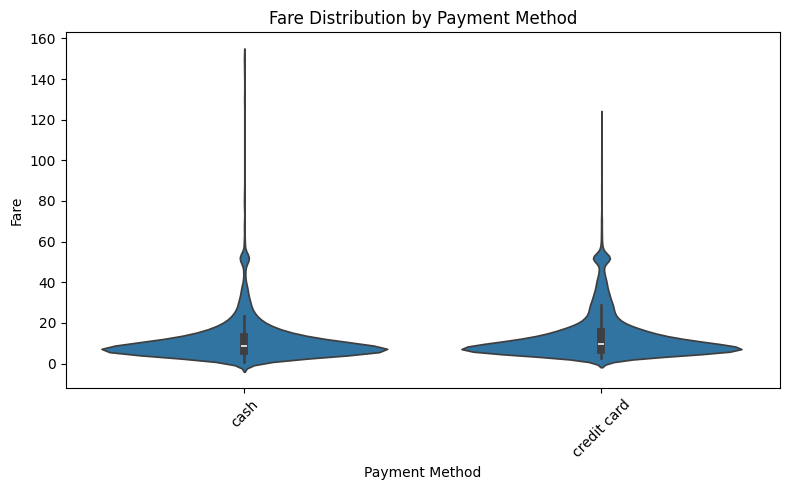

In [14]:
# 4.5 Violin Plot – Fare by Payment Method
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=df,
    x="payment",
    y="fare"
)

plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The violin plot compares fare distributions for different payment methods. The width of each violin indicates where fare values are more concentrated.